# Week 11 — Quantifying a Segmentation: Volume & Shape

Once you have a **3-D segmentation mask** (from ITK-SNAP, ParaView, or an AI model), the next step is
to turn it into **numbers**: a physical **volume** and **shape descriptors**. This is the core
measurement step for several class projects (hippocampus volume, left-ventricle volume over time,
optic-nerve-head vessel morphology).

**Key ideas**
- **Volume = (voxel physical volume) × (number of foreground voxels)** — the voxel spacing (mm) comes
  from the DICOM/NIfTI header.
- **Shape metrics** (elongation, roundness/sphericity, flatness, principal-axis lengths) distinguish a
  **blob**-like object from a **tubular** one — the 3-D analogue of MATLAB's `regionprops`.

We build a synthetic two-label mask (an ellipsoid “ventricle” + a cylindrical “vessel”) and quantify
both with **SimpleITK** and **scikit-image**.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import SimpleITK as sitk
from skimage.measure import regionprops_table, marching_cubes, mesh_surface_area

plt.rcParams["figure.dpi"] = 110

# Synthetic 3-D label mask on a grid with known voxel spacing (from the image header)
spacing = (0.5, 0.5, 0.5)                       # mm per voxel (z, y, x)
Z, Y, X = np.mgrid[:60, :80, :80]
ellipsoid = (((X - 40) / 22) ** 2 + ((Y - 40) / 16) ** 2 + ((Z - 30) / 12) ** 2) <= 1   # 'ventricle'
vessel = ((Y - 18) ** 2 + (Z - 48) ** 2 <= 4 ** 2) & (X >= 12) & (X <= 64)              # 'vessel'

mask = np.zeros(Z.shape, np.uint8)
mask[ellipsoid] = 1
mask[vessel] = 2
labels = {1: "ellipsoid (blob)", 2: "cylinder (vessel)"}
print(f"mask {mask.shape}, spacing {spacing} mm, labels {sorted(labels)}")

mask (60, 80, 80), spacing (0.5, 0.5, 0.5) mm, labels [1, 2]


In [2]:
# Write the labeled volume to a NIfTI file (opens in ITK-SNAP / ParaView)
seg = sitk.GetImageFromArray(mask)          # (z, y, x) numpy array -> image
seg.SetSpacing(spacing[::-1])               # SimpleITK expects (x, y, z) order
nii_path = "segmentation_mask.nii.gz"
sitk.WriteImage(seg, nii_path)
print(f"wrote {nii_path}: shape={mask.shape}, spacing(x,y,z)={seg.GetSpacing()} mm")

wrote segmentation_mask.nii.gz: shape=(60, 80, 80), spacing(x,y,z)=(0.5, 0.5, 0.5) mm


## 1. Volume by voxel counting

The simplest and most robust volume estimate: count the foreground voxels of a label and multiply by
the physical volume of one voxel ($\Delta x\,\Delta y\,\Delta z$). Divide by 1000 to get **mL** (since
$1\text{ mL}=1000\text{ mm}^3$).

In [3]:
voxel_volume_mm3 = float(np.prod(spacing))
print(f"one voxel = {voxel_volume_mm3:.4f} mm^3\n")
for lab, name in labels.items():
    n = int((mask == lab).sum())
    vol_mm3 = n * voxel_volume_mm3
    print(f"label {lab} ({name}): {n:6d} voxels  ->  {vol_mm3:8.1f} mm^3  =  {vol_mm3/1000:.3f} mL")

one voxel = 0.1250 mm^3

label 1 (ellipsoid (blob)):  17601 voxels  ->    2200.1 mm^3  =  2.200 mL
label 2 (cylinder (vessel)):   2597 voxels  ->     324.6 mm^3  =  0.325 mL


## 2. Shape metrics with SimpleITK

`LabelShapeStatisticsImageFilter` reads the voxel spacing from the image and reports physically
meaningful descriptors per label:
- **Physical size** (volume) — matches the voxel-count result,
- **Elongation** (major/middle axis ratio) and **Flatness** (middle/minor) — 1.0 = isotropic,
- **Roundness** — 1.0 for a perfect sphere,
- **Equivalent spherical radius** — radius of a sphere of the same volume.

In [4]:
img = sitk.GetImageFromArray(mask)
img.SetSpacing(spacing[::-1])                   # SimpleITK uses (x, y, z) order
stats = sitk.LabelShapeStatisticsImageFilter()
stats.Execute(img)

print(f"{'label':22s}{'volume mm^3':>12s}{'elongation':>12s}{'roundness':>11s}{'flatness':>10s}{'eq.R mm':>9s}")
for lab, name in labels.items():
    print(f"{name:22s}{stats.GetPhysicalSize(lab):12.1f}{stats.GetElongation(lab):12.2f}"
          f"{stats.GetRoundness(lab):11.2f}{stats.GetFlatness(lab):10.2f}"
          f"{stats.GetEquivalentSphericalRadius(lab):9.2f}")

label                  volume mm^3  elongation  roundness  flatness  eq.R mm
ellipsoid (blob)            2200.1        1.38       0.96      1.34     8.07
cylinder (vessel)            324.6        7.73       0.63      1.00     4.26


## 3. Shape metrics with scikit-image, and sphericity

`regionprops` gives axis lengths, solidity, and extent; for **sphericity** we triangulate the surface
with **marching cubes** and use
$$\psi = \frac{\pi^{1/3}\,(6V)^{2/3}}{A},$$
which is **1 for a sphere** and drops toward 0 for elongated/irregular shapes. A **blob** has high
sphericity and low elongation; a **tube** is the opposite.

In [5]:
def sphericity(binary, spacing):
    verts, faces, _, _ = marching_cubes(binary.astype(float), level=0.5, spacing=spacing)
    area = mesh_surface_area(verts, faces)
    vol = binary.sum() * float(np.prod(spacing))
    return (np.pi ** (1 / 3)) * ((6 * vol) ** (2 / 3)) / area

rows = {}
for lab, name in labels.items():
    binary = (mask == lab)
    props = regionprops_table(binary.astype(int),
                              properties=("axis_major_length", "axis_minor_length", "solidity"))
    rows[name] = {
        "major axis (vox)": round(float(props["axis_major_length"][0]), 1),
        "minor axis (vox)": round(float(props["axis_minor_length"][0]), 1),
        "solidity": round(float(props["solidity"][0]), 3),
        "sphericity": round(sphericity(binary, spacing), 3),
    }
for name, r in rows.items():
    print(f"{name:22s} {r}")

ellipsoid (blob)       {'major axis (vox)': 44.0, 'minor axis (vox)': 23.9, 'solidity': 0.946, 'sphericity': np.float64(0.88)}
cylinder (vessel)      {'major axis (vox)': 68.4, 'minor axis (vox)': 8.9, 'solidity': 0.86, 'sphericity': np.float64(0.587)}


## 4. Visualize and interpret

Maximum-intensity projections show the two shapes; the bar chart contrasts their descriptors. The
**blob** is round and compact (sphericity near 1, elongation near 1); the **vessel** is highly
elongated with low sphericity — exactly the signal you would use to characterize vessel tortuosity or
to confirm a compact ventricle segmentation.

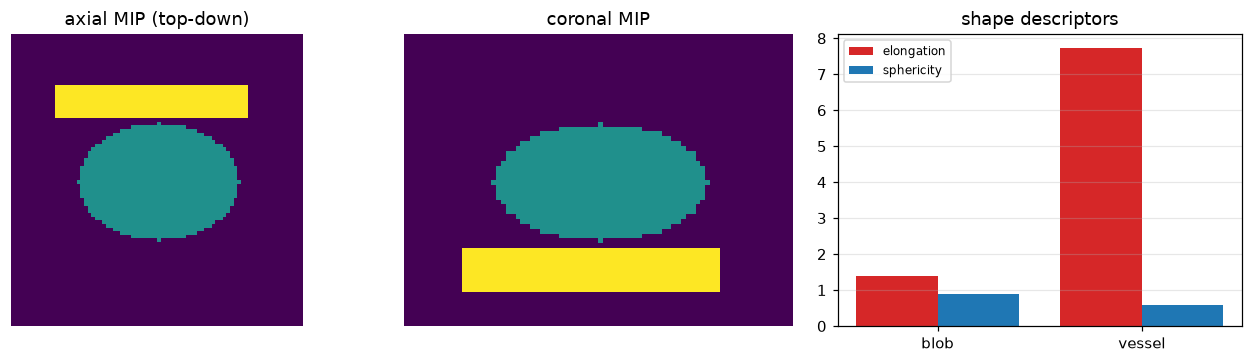

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
ax[0].imshow(mask.max(axis=0), cmap="viridis"); ax[0].set_title("axial MIP (top-down)"); ax[0].axis("off")
ax[1].imshow(mask.max(axis=1), cmap="viridis"); ax[1].set_title("coronal MIP"); ax[1].axis("off")

names = list(rows)
elong = [stats.GetElongation(lab) for lab in labels]
spher = [rows[n]["sphericity"] for n in names]
xpos = np.arange(len(names))
ax[2].bar(xpos - 0.2, elong, 0.4, label="elongation", color="tab:red")
ax[2].bar(xpos + 0.2, spher, 0.4, label="sphericity", color="tab:blue")
ax[2].set_xticks(xpos); ax[2].set_xticklabels(["blob", "vessel"]); ax[2].legend(fontsize=8)
ax[2].set_title("shape descriptors"); ax[2].grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.show()

## Takeaways

- **Volume** needs only the mask and the **voxel spacing**: $V = N_\text{voxels}\times \Delta x\Delta y\Delta z$.
  Export the mask from ITK-SNAP/ParaView as NIfTI/VTK and count per label.
- **SimpleITK** `LabelShapeStatisticsImageFilter` gives volume, elongation, roundness, flatness, and
  equivalent radius straight from the labelled image (spacing-aware).
- **Sphericity** $\psi=\pi^{1/3}(6V)^{2/3}/A$ (from a marching-cubes surface) separates **blobs**
  (ψ→1) from **tubes** (ψ small).
- Repeat the volume over **time frames** to get a left-ventricle volume curve (and ejection fraction);
  repeat per **subject** to compare groups (see *ComparingTwoGroups.ipynb*).